# Preprocessing pipeline for the intracellular metabolomics dataset

## Overview :

This notebook implements the preprocessing workflow applied to the cellular LC–HRMS metabolomics dataset generated from HepaRG cells exposed to psychostimulants.

The objective is to obtain a high-quality feature matrix suitable for downstream statistical analyses by applying successive cleaning, filtering, and correction steps.

The workflow includes:
1. Feature cleaning - Removal of redundant signals;
2. Feature cleaning - Removal of exogenous signals;
3. Data structuring;
4. QC detection filter;
5. Intra-batch drift correction;
6. QC reliability filter;
7. Inter-batch correction;
8. Final removal of non-informative features;
9. PCA quality assessement on QC.


# 0. Environment and analysis configuration

In [5]:
# Data handling
import os
import re
import csv
import pandas as pd
import numpy as np
from pathlib import Path

# Data visualization
import matplotlib.pyplot as plt

# Signal correction
from statsmodels.nonparametric.smoothers_lowess import lowess

# Parallel computing and progress tracking
from joblib import Parallel, delayed
from tqdm import tqdm

# Multivariate quality control
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [6]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Main project folders
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_METADATA = PROJECT_ROOT / "data" / "metadata"
DATA_DATABASES = PROJECT_ROOT / "data" / "databases"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
OUTPUT_FIGURES = PROJECT_ROOT / "outputs" / "figures"/ "preprocessing_analysis"

# Create output folders if needed
DATA_RAW.mkdir(parents=True, exist_ok=True)
DATA_METADATA.mkdir(parents=True, exist_ok=True)
DATA_DATABASES.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data folder: {DATA_RAW}")
print(f"Metadata folder: {DATA_METADATA}")
print(f"Database folder: {DATA_DATABASES}")
print(f"Processed data folder: {DATA_PROCESSED}")
print(f"Output figures folder: {OUTPUT_FIGURES}")

Project root: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE
Raw data folder: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\raw
Metadata folder: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\metadata
Database folder: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\databases
Processed data folder: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed
Output figures folder: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\figures\preprocessing_analysis


# 1. Removal of redundant analytical features based on MZmine correlation groups

Features assigned to the same MZmine correlation group were considered as potentially redundant analytical signals, including adducts or in-source fragments. For each correlation group, the feature with the highest mean peak area across all samples was retained as the representative signal. Ungrouped features were kept unchanged.

In [7]:
# ---------- Input / output files ----------
input_file = DATA_RAW / "CELL_export_mzmine.csv"
output_file = DATA_PROCESSED / "01_CELL_representative_features.xlsx"

# Create output directory if needed
output_file.parent.mkdir(parents=True, exist_ok=True)

# ---------- Check input file ----------
if not input_file.exists():
    raise FileNotFoundError(f"Input file not found: {input_file}\n Please place the raw MZmine export in data/raw/.")

# ---------- Load raw MZmine table ----------
df = pd.read_csv(input_file, sep=";")

# Remove empty columns generated by trailing separators, if present
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

# ---------- Identify intensity columns ----------
intensity_cols = [col for col in df.columns if col.endswith("_RPPOS.mzXML Peak area")]

if len(intensity_cols) == 0:
    raise ValueError("No intensity columns were found. Please check the suffix used for peak area columns.")

# ---------- Check required columns ----------
required_cols = ["correlation group ID"]
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise ValueError(f"Missing required column(s): {missing_cols}")

# ---------- Compute mean intensity per feature ----------
df["mean_intensity"] = df[intensity_cols].mean(axis=1, skipna=True)

# ---------- Split grouped and ungrouped features ----------
grouped_features = df[df["correlation group ID"].notna()].copy()

ungrouped_features = df[df["correlation group ID"].isna()].copy()

# ---------- Select one representative feature per correlation group ----------
# The representative feature is the one with the highest mean intensity.
representative_idx = (grouped_features.groupby("correlation group ID")["mean_intensity"].idxmax())
representative_features = grouped_features.loc[representative_idx].copy()

# ---------- Identify removed redundant features ----------
removed_features = grouped_features.drop(index=representative_idx).copy()

removed_features["removal_reason"] = ("Redundant feature within MZmine correlation group; lower mean intensity than selected representative feature")

# ---------- Recombine representative grouped features and ungrouped features ----------
df_clean = pd.concat([representative_features, ungrouped_features], ignore_index=True)

# ---------- Prepare summary ----------
summary = pd.DataFrame({"step": ["Initial features", "Grouped features", "Correlation groups", "Ungrouped features", "Removed redundant features", "Final"],
                        "n_features": [df.shape[0], grouped_features.shape[0], grouped_features["correlation group ID"].nunique(), 
                                       ungrouped_features.shape[0], removed_features.shape[0], df_clean.shape[0]]})

# ---------- Remove temporary column before export ----------
df_clean = df_clean.drop(columns=["mean_intensity"])
removed_features = removed_features.drop(columns=["mean_intensity"])

# ---------- Export one Excel file with multiple sheets ----------
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    df_clean.to_excel(writer, sheet_name="representative_features", index=False)
    removed_features.to_excel(writer, sheet_name="removed_features", index=False)
    summary.to_excel(writer, sheet_name="summary", index=False)

# ---------- Display summary ----------
print(summary.to_string(index=False))
print(f"\nStep 1 completed.")
print(f"Output file exported to: {output_file}")

                      step  n_features
          Initial features        4065
          Grouped features        1334
        Correlation groups         475
        Ungrouped features        2731
Removed redundant features         859
   Final retained features        3206

Step 1 completed.
Output file exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\01_CELL_representative_features_S.xlsx


# 2. Removal of contaminant and exogenous compound-related features

An internal database containing contaminant and exogenous compound-related features was used to remove non-endogenous signals from the intracellular metabolomics dataset. Features listed in the `DTB_READY` sheet were removed based on their MZmine row ID. The resulting dataset was used as the curated endogenous feature matrix for subsequent preprocessing steps.

In [8]:
# ============================================================
# 2. Removal of contaminant and exogenous compound-related features
# ============================================================

# ---------- Input / output files ----------
input_file = DATA_PROCESSED / "01_CELL_representative_features.xlsx"
dtb_file = DATA_DATABASES / "DTB_contaminants_exogenous_features.xlsx"
output_file = DATA_PROCESSED / "02_CELL_endogenous_features.xlsx"

# Create output directory if needed
output_file.parent.mkdir(parents=True, exist_ok=True)

# ---------- Check input files ----------
if not input_file.exists():
    raise FileNotFoundError( f"Input file not found: {input_file}\n Please run Step 1 first or check the processed data folder.")

if not dtb_file.exists():
    raise FileNotFoundError(f"DTB file not found: {dtb_file}\n Please place the contaminant/exogenous feature database in data/databases/.")

# ---------- Load data ----------
feature_table = pd.read_excel(input_file, sheet_name="representative_features")
dtb = pd.read_excel(dtb_file, sheet_name="DTB_READY")

# Remove empty columns, if present
feature_table = feature_table.loc[:, ~feature_table.columns.str.startswith("Unnamed")]
dtb = dtb.loc[:, ~dtb.columns.str.startswith("Unnamed")]

# ---------- Check required columns ----------
required_feature_cols = ["row ID"]
required_dtb_cols = ["Feature"]

missing_feature_cols = [col for col in required_feature_cols if col not in feature_table.columns]
missing_dtb_cols = [col for col in required_dtb_cols if col not in dtb.columns]

if missing_feature_cols:
    raise ValueError(f"Missing required column(s) in feature table: {missing_feature_cols}")

if missing_dtb_cols:
    raise ValueError(f"Missing required column(s) in DTB file: {missing_dtb_cols}")

# ---------- Convert feature IDs ----------
feature_table["row ID"] = pd.to_numeric(feature_table["row ID"], errors="coerce").astype("Int64")
dtb["Feature"] = pd.to_numeric(dtb["Feature"], errors="coerce").astype("Int64")

# ---------- Check missing or non-numeric IDs ----------
n_missing_row_ids = feature_table["row ID"].isna().sum()
n_missing_dtb_ids = dtb["Feature"].isna().sum()

if n_missing_row_ids > 0:
    print(f"Warning: {n_missing_row_ids} missing or non-numeric row ID(s) found in the feature table.")

if n_missing_dtb_ids > 0:
    print(f"Warning: {n_missing_dtb_ids} missing or non-numeric Feature ID(s) found in the DTB.")

# ---------- Prepare feature IDs to remove ----------
dtb_feature_ids = (dtb["Feature"].dropna().astype(int).unique())
feature_ids_in_table = (feature_table["row ID"].dropna().astype(int).unique())

# ---------- Identify unmatched DTB IDs ----------
unmatched_dtb_ids = sorted(set(dtb_feature_ids) - set(feature_ids_in_table))
unmatched_dtb = pd.DataFrame({"Feature": unmatched_dtb_ids, "comment": "Feature ID listed in DTB but not found in input feature table"})

# ---------- Remove contaminant / exogenous features ----------
n_before = feature_table.shape[0]

removed_features = feature_table[feature_table["row ID"].isin(dtb_feature_ids)].copy()
endogenous_features = feature_table[~feature_table["row ID"].isin(dtb_feature_ids)].copy()

n_removed = removed_features.shape[0]
n_after = endogenous_features.shape[0]

# ---------- Add removal reason ----------
removed_features["removal_reason"] = ("Feature listed in internal contaminant/exogenous compound database")

# ---------- Summary table ----------
summary = pd.DataFrame({"step": ["Input features after correlation group filtering",
                                 "Unique feature IDs listed in DTB",
                                 "DTB feature IDs found in input table",
                                 "DTB feature IDs not found in input table",
                                 "Features removed",
                                 "Final endogenous features"],
                        "n_features": [n_before, 
                                       len(dtb_feature_ids), 
                                       len(set(dtb_feature_ids).intersection(set(feature_ids_in_table))),
                                       len(unmatched_dtb_ids),
                                       n_removed,
                                       n_after]})

# ---------- Export one Excel file with multiple sheets ----------
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    endogenous_features.to_excel(writer, sheet_name="endogenous_features", index=False)
    removed_features.to_excel(writer, sheet_name="removed_features", index=False)
    unmatched_dtb.to_excel(writer, sheet_name="unmatched_DTB_IDs", index=False)
    summary.to_excel(writer, sheet_name="summary", index=False)
    
# ---------- Display summary ----------
print(summary.to_string(index=False))
print(f"\nStep 2 completed.")
print(f"Output file exported to: {output_file}")

                                            step  n_features
Input features after correlation group filtering        3206
                Unique feature IDs listed in DTB         500
            DTB feature IDs found in input table         399
        DTB feature IDs not found in input table         101
                                Features removed         399
                       Final endogenous features        2807

Step 2 completed.
Output file exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\02_CELL_endogenous_features_S.xlsx


# 3. Data formatting and sample metadata extraction

The endogenous feature table was reformatted into a sample-by-feature matrix. Sample metadata, including batch, sample type, experiment, drug, exposure time and replicate information, were extracted from the raw sample names. Injection order metadata were then added to support downstream intra-batch signal drift correction.

In [9]:
# ---------- Input / output files ----------
input_file = DATA_PROCESSED / "02_CELL_endogenous_features.xlsx"
order_file = DATA_METADATA / "CELL_injection_order.xlsx"
formatted_file = DATA_PROCESSED / "03_CELL_formatted_dataset.xlsx"

# Create output directory if needed
formatted_file.parent.mkdir(parents=True, exist_ok=True)

# ---------- Check input files ----------
if not input_file.exists():
    raise FileNotFoundError(f"Input file not found: {input_file}\n Please run Step 2 first or check the processed data folder.")

if not order_file.exists():
    raise FileNotFoundError(f"Injection order file not found: {order_file}\n Please place CELL_injection_order.xlsx in data/metadata/.")

# ---------- Load endogenous feature table ----------
feature_table = pd.read_excel(input_file, sheet_name="endogenous_features")

# Remove empty columns, if present
feature_table = feature_table.loc[:, ~feature_table.columns.str.startswith("Unnamed")]

# ---------- Define feature metadata columns ----------
feature_metadata_cols = ["correlation group ID", "row ID", "row identity (main ID)", "row m/z", "row retention time"]
feature_metadata_cols = [col for col in feature_metadata_cols if col in feature_table.columns]

if "row ID" not in feature_table.columns:
    raise ValueError("Missing required column in feature table: row ID")

# ---------- Identify intensity columns ----------
intensity_suffix = "_RPPOS.mzXML Peak area"

intensity_cols = [col for col in feature_table.columns if col.endswith(intensity_suffix)]

if len(intensity_cols) == 0:
    raise ValueError("No intensity columns were found. Please check the suffix used for peak area columns.")

# ---------- Helper functions ----------
def clean_sample_name(sample_column):
    """
    Remove the MZmine intensity suffix from a sample column name.
    """
    return str(sample_column).replace(intensity_suffix, "").strip()


def extract_time_h(time_label):
    """
    Extract numeric exposure time from labels such as T1, T3, T6, T8, T12 or T24.
    Returns NaN if no numeric value is found.
    """
    match = re.search(r"\d+", str(time_label))
    if match:
        return int(match.group())
    return np.nan


# ---------- Extract sample metadata from MZmine column names ----------
sample_info = []

for col in intensity_cols:
    sample_id = clean_sample_name(col)
    parts = sample_id.split("-")

    if len(parts) < 2:
        raise ValueError(f"Unexpected sample name format: {sample_id}. Expected at least: batch-type-...")

    batch = parts[0]
    sample_type = parts[1]

    sample = {
        "sample_id": sample_id,
        "raw_column": col,
        "batch": batch,
        "sample_type": sample_type,
        "condition": np.nan,
        "experiment": np.nan,
        "drug": np.nan,
        "time": np.nan,
        "time_h": np.nan,
        "dilution": np.nan,
        "replicate": np.nan,
        "sample_group": np.nan}

    if sample_type == "CQ":
        if len(parts) < 5:
            raise ValueError(f"Unexpected QC sample name format: {sample_id}. Expected format similar to: batch-CQ-1-dilution-replicate")
        sample["condition"] = "CQ"
        sample["dilution"] = parts[3]
        sample["replicate"] = parts[4]
        sample["sample_group"] = f"CQ-1-{parts[3]}"

    elif sample_type == "CELL":
        if len(parts) < 5:
            raise ValueError(f"Unexpected CELL sample name format: {sample_id}. Expected format similar to: batch-CELL-experiment-drug-time")
        sample["condition"] = "CELL"
        sample["experiment"] = parts[2]
        sample["drug"] = parts[3]
        sample["time"] = parts[4]
        sample["time_h"] = extract_time_h(parts[4])
        sample["replicate"] = parts[2]
        sample["sample_group"] = f"{parts[3]}-{parts[4]}"

    else:
        sample["condition"] = sample_type
        sample["sample_group"] = sample_type

    sample_info.append(sample)

sample_metadata = pd.DataFrame(sample_info)

# ---------- Build sample-by-feature intensity matrix ----------
intensity_matrix = feature_table[intensity_cols].transpose()

intensity_matrix.index = [clean_sample_name(col) for col in intensity_cols]
intensity_matrix.index.name = "sample_id"

# Use row ID as feature identifier
intensity_matrix.columns = feature_table["row ID"].astype(str)

# ---------- Load cleaned injection order file ----------
injection_order = pd.read_excel(order_file, sheet_name="CELL_injection_order")
required_order_cols = ["sample_id", "injection_order"]
missing_order_cols = [col for col in required_order_cols if col not in injection_order.columns]

if missing_order_cols:
    raise ValueError(f"Missing required column(s) in injection order file: {missing_order_cols}")

injection_order["sample_id"] = (injection_order["sample_id"].astype(str).str.strip())
injection_order["injection_order"] = pd.to_numeric(injection_order["injection_order"], errors="coerce")

# ---------- Check duplicated sample IDs in injection order ----------
duplicated_order_samples = injection_order[injection_order["sample_id"].duplicated(keep=False)]

if not duplicated_order_samples.empty:
    raise ValueError("Duplicated sample IDs found in injection order file:\n" f"{duplicated_order_samples['sample_id'].tolist()}")

# ---------- Add injection order to sample metadata ----------
sample_metadata = sample_metadata.merge(injection_order[["sample_id", "injection_order"]], on="sample_id", how="left")

n_samples = sample_metadata.shape[0]
n_with_order = sample_metadata["injection_order"].notna().sum()
n_without_order = n_samples - n_with_order

if n_without_order > 0:
    missing_order_samples = sample_metadata.loc[sample_metadata["injection_order"].isna(), "sample_id"].tolist()

    print(f"Warning: {n_without_order} sample(s) have no injection order assigned.")
    print("Samples without injection order:")
    print(missing_order_samples)

# ---------- Combine metadata and intensity matrix ----------
formatted_data = sample_metadata.set_index("sample_id").join(intensity_matrix, how="left")

# ---------- Extract feature metadata ----------
feature_metadata = feature_table[feature_metadata_cols].copy()

# ---------- Summary table ----------
summary = pd.DataFrame({"item": ["Endogenous features", 
                                 "Intensity columns / samples", 
                                 "Samples with injection order",
                                 "Samples without injection order",
                                 "Feature metadata columns retained"],
                        "n": [feature_table.shape[0],
                              len(intensity_cols),
                              n_with_order,
                              n_without_order,
                              len(feature_metadata_cols)]})

# ---------- Export one Excel file with multiple sheets ----------
with pd.ExcelWriter(formatted_file, engine="openpyxl") as writer:
    formatted_data.to_excel(writer, sheet_name="formatted_data")

    sample_metadata.to_excel(writer, sheet_name="sample_metadata", index=False)
    intensity_matrix.to_excel(writer, sheet_name="intensity_matrix")
    feature_metadata.to_excel(writer, sheet_name="feature_metadata", index=False)
    summary.to_excel(writer, sheet_name="summary", index=False)

# ---------- Display summary ----------
print(summary.to_string(index=False))
print(f"\nStep 3 completed.")
print(f"Output file exported to: {formatted_file}")

                             item    n
              Endogenous features 2807
      Intensity columns / samples  212
     Samples with injection order  212
  Samples without injection order    0
Feature metadata columns retained    5

Step 3 completed.
Output file exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\03_CELL_formatted_dataset_S.xlsx


# 4. First feature filtering based on QC detectability before intra-batch correction

Features with a mean intensity equal to zero in the reference QC group (`CQ-1-1`) in at least one analytical batch were removed before intra-batch signal drift correction.

In [11]:
# ---------- Parameters ----------
QC_LABEL = "CQ-1-1"
ZERO_FILTER_MODE = "any_batch"  
# Options:
# "any_batch" = remove feature if QC mean is 0 in at least one batch
# "all_batches" = remove feature only if QC mean is 0 in all batches

# ---------- Input / output files ----------
input_file = DATA_PROCESSED / "03_CELL_formatted_dataset.xlsx"
output_file = DATA_PROCESSED / "04_CELL_filter1_qc_mean_nonzero.xlsx"
# Create output directory if needed
output_file.parent.mkdir(parents=True, exist_ok=True)

# ---------- Check input file ----------
if not input_file.exists():
    raise FileNotFoundError(f"Input file not found: {input_file}\n Please run Step 3 first or check the processed data folder.")

# ---------- Load formatted dataset ----------
data = pd.read_excel(input_file, sheet_name="formatted_data")

# Remove empty columns, if present
data = data.loc[:, ~data.columns.str.startswith("Unnamed")]

# ---------- Required metadata columns ----------
required_cols = ["batch", "sample_group"]

missing_cols = [col for col in required_cols if col not in data.columns]

if missing_cols:
    raise ValueError(f"Missing required column(s): {missing_cols}")

# ---------- Identify metadata and feature columns ----------
metadata_cols = [
    "sample_id",
    "raw_column",
    "batch",
    "sample_type",
    "condition",
    "experiment",
    "drug",
    "time",
    "time_h",
    "dilution",
    "replicate",
    "sample_group",
    "injection_order"
]

metadata_cols = [col for col in metadata_cols if col in data.columns]

feature_cols = [col for col in data.columns if col not in metadata_cols]

if len(feature_cols) == 0:
    raise ValueError("No feature columns were detected after metadata column exclusion.")

print(f"Input features detected: {len(feature_cols)}")

# ---------- Extract reference QC samples ----------
qc_data = data.loc[data["sample_group"] == QC_LABEL, ["batch"] + feature_cols].copy()

if qc_data.empty:
    raise ValueError(f"No QC samples found with sample_group == '{QC_LABEL}'. Please check the sample metadata.")

qc_data["batch"] = qc_data["batch"].astype(str)

# Convert feature intensities to numeric values
qc_data[feature_cols] = qc_data[feature_cols].apply(pd.to_numeric, errors="coerce")
batches = sorted(qc_data["batch"].dropna().unique())

if len(batches) == 0:
    raise ValueError("No batch information found for QC samples.")

print(f"Batches found for QC group {QC_LABEL}: {batches}")

# ---------- Compute mean QC intensity by batch ----------
qc_mean = (qc_data.groupby("batch")[feature_cols].mean(numeric_only=True))

# ---------- Identify features to remove ----------
if ZERO_FILTER_MODE == "any_batch":
    features_to_remove = qc_mean.columns[(qc_mean == 0).any(axis=0)].tolist()
    filter_rule = (f"QC mean intensity equal to 0 in at least one batch for QC group {QC_LABEL}")

elif ZERO_FILTER_MODE == "all_batches":
    features_to_remove = qc_mean.columns[(qc_mean == 0).all(axis=0)].tolist()
    filter_rule = (f"QC mean intensity equal to 0 in all batches for QC group {QC_LABEL}")

else:
    raise ValueError("Invalid ZERO_FILTER_MODE. Use 'any_batch' or 'all_batches'.")
features_to_keep = [feature for feature in feature_cols if feature not in features_to_remove]

# ---------- Create cleaned dataset ----------
clean_data = data[metadata_cols + features_to_keep].copy()

# ---------- Create removed feature table ----------
if len(features_to_remove) > 0:
    zero_mask = qc_mean[features_to_remove] == 0
    removed_info = []
    for feature in features_to_remove:
        zero_batches = zero_mask.index[zero_mask[feature]].tolist()
        removed_info.append({"feature": feature, "removal_reason": filter_rule, "zero_mean_batch(es)": ",".join(map(str, zero_batches))})
    removed_features = pd.DataFrame(removed_info)

else:
    removed_features = pd.DataFrame(columns=["feature", "removal_reason", "zero_mean_batch(es)"])

# ---------- Summary table ----------
summary = pd.DataFrame({"item": ["Input features","Reference QC group", "Analytical batches", "Filtering rule", "Removed features", "Retained features"],
                        "value": [ len(feature_cols), QC_LABEL, ", ".join(map(str, batches)), filter_rule, len(features_to_remove), len(features_to_keep)]})

with pd.ExcelWriter(output_file) as writer:
    clean_data.to_excel(writer, sheet_name="filtered_data", index=False)
    removed_features.to_excel(writer, sheet_name="removed_features", index=False)
    qc_mean.to_excel(writer, sheet_name="qc_mean_by_batch")
    summary.to_excel(writer, sheet_name="summary", index=False)

# ---------- Display summary ----------
print(summary.to_string(index=False))
print(f"\nFiltered dataset exported to: {output_file}")

Input features detected: 2807
Batches found for QC group CQ-1-1: ['200625', '40725']
              item                                                                  value
    Input features                                                                   2807
Reference QC group                                                                 CQ-1-1
Analytical batches                                                          200625, 40725
    Filtering rule QC mean intensity equal to 0 in at least one batch for QC group CQ-1-1
  Removed features                                                                    741
 Retained features                                                                   2066

Filtered dataset exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\04_CELL_filter1_qc_mean_nonzero_S.xlsx


# 5. Intra-batch signal drift correction using QC-RLSC

Signal drift was corrected independently within each analytical batch using QC-based robust LOESS signal correction. For each feature and each batch, a LOWESS curve was fitted on reference QC samples (`CQ-1-1`) according to injection order. Intensities were then corrected by multiplicative normalization using the mean observed QC intensity as reference.

In [12]:
# ---------- Parameters ----------
QC_LABEL = "CQ-1-1"
MIN_QC_POINTS = 8
LOWESS_FRAC = 0.5
N_JOBS = -1

# ---------- Input / output files ----------
input_file = DATA_PROCESSED / "04_CELL_filter1_qc_mean_nonzero.xlsx"
output_file = DATA_PROCESSED / "05_CELL_qcrlsc_corrected.xlsx"

# Create output directory if needed
output_file.parent.mkdir(parents=True, exist_ok=True)

# ---------- Check input file ----------
if not input_file.exists():
    raise FileNotFoundError(f"Input file not found: {input_file}\n Please run Step 4 first or check the processed data folder.")
    
# ---------- Load filtered dataset ----------
data = pd.read_excel(input_file, sheet_name="filtered_data")

# Remove empty columns, if present
data = data.loc[:, ~data.columns.str.startswith("Unnamed")]

# ---------- Required metadata columns ----------
required_cols = ["batch", "sample_group", "injection_order"]

missing_cols = [col for col in required_cols if col not in data.columns]

if missing_cols:
    raise ValueError(f"Missing required column(s): {missing_cols}")

# ---------- Identify metadata and feature columns ----------
metadata_cols = [
    "sample_id",
    "raw_column",
    "batch",
    "sample_type",
    "condition",
    "experiment",
    "drug",
    "time",
    "time_h",
    "dilution",
    "replicate",
    "sample_group",
    "injection_order"]

metadata_cols = [col for col in metadata_cols if col in data.columns]

feature_cols = [col for col in data.columns if col not in metadata_cols]

if len(feature_cols) == 0:
    raise ValueError("No feature columns were detected after metadata column exclusion.")

# ---------- Convert numeric columns ----------
data["injection_order"] = pd.to_numeric(data["injection_order"], errors="coerce")

data[feature_cols] = data[feature_cols].apply(pd.to_numeric, errors="coerce")

if data["injection_order"].isna().any():
    missing_order_samples = data.loc[data["injection_order"].isna(), "sample_id" if "sample_id" in data.columns else "sample_group"].tolist()
    raise ValueError(f"Some samples have missing or non-numeric injection order values:\n {missing_order_samples}")

print(f"Input features detected: {len(feature_cols)}")
print(f"QC label used for correction: {QC_LABEL}")
print(f"Minimum QC points required per feature and batch: {MIN_QC_POINTS}")
print(f"LOWESS fraction: {LOWESS_FRAC}")


# ---------- Helper functions ----------
def rsd_percent(values):
    """
    Compute relative standard deviation in percent.
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size < 2:
        return np.nan
    mean_value = np.mean(values)
    if mean_value == 0:
        return np.nan
    return 100.0 * np.std(values, ddof=1) / mean_value

def prepare_xy_unique(x_values, y_values):
    """
    Sort x/y values and aggregate duplicated injection orders using the mean.
    """
    x_values = np.asarray(x_values, dtype=float)
    y_values = np.asarray(y_values, dtype=float)
    order = np.argsort(x_values)
    x_sorted = x_values[order]
    y_sorted = y_values[order]
    x_unique = np.unique(x_sorted)
    y_aggregated = np.array([np.mean(y_sorted[x_sorted == x_val]) for x_val in x_unique], dtype=float)
    return x_unique, y_aggregated

def fit_lowess_curve(x_qc, y_qc, frac):
    """
    Fit a LOWESS curve using QC samples.
    """
    x_fit, y_input = prepare_xy_unique(x_qc, y_qc)
    y_fit = lowess(y_input, x_fit, frac=float(frac), is_sorted=True, return_sorted=False)
    return x_fit, y_fit

def interpolate_lowess(x_fit, y_fit, x_new):
    """
    Predict LOWESS-fitted values by linear interpolation.
    Border values are used for extrapolation.
    """
    x_new = np.asarray(x_new, dtype=float)
    return np.interp(x_new, x_fit, y_fit)

def apply_multiplicative_correction(y_all, y_pred_all, reference_mean):
    """
    Apply multiplicative QC-RLSC correction.
    """
    eps = 1e-12
    y_all = np.asarray(y_all, dtype=float)
    y_pred_all = np.asarray(y_pred_all, dtype=float)
    invalid_prediction = ((~np.isfinite(y_pred_all)) | (y_pred_all <= eps))
    y_pred_all = np.where(invalid_prediction, np.nan, y_pred_all)
    return y_all / y_pred_all * reference_mean

def process_feature_one_batch(batch_data, feature):
    """
    Correct one feature within one analytical batch.
    """
    x_all = batch_data["injection_order"].to_numpy(dtype=float)
    y_all = batch_data[feature].to_numpy(dtype=float)
    qc_mask = (batch_data["sample_group"] == QC_LABEL).to_numpy()
    x_qc = x_all[qc_mask]
    y_qc = y_all[qc_mask]

    # Keep only valid QC points
    valid_qc = (np.isfinite(x_qc) & np.isfinite(y_qc))
    x_qc = x_qc[valid_qc]
    y_qc = y_qc[valid_qc]
    n_qc = y_qc.size

    if n_qc < MIN_QC_POINTS:
        return {"feature": feature,
            "corrected_values": y_all,
            "RSD_QC_before_%": np.nan,
            "RSD_QC_after_%": np.nan,
            "n_qc_valid": n_qc,
            "status": "not_enough_qc"}

    rsd_before = rsd_percent(y_qc)

    if np.nanstd(y_qc) < 1e-12:
        return {"feature": feature,
            "corrected_values": y_all,
            "RSD_QC_before_%": rsd_before,
            "RSD_QC_after_%": rsd_before,
            "n_qc_valid": n_qc,
            "status": "qc_flat"}
    try:
        # Fit LOWESS using QC samples
        x_fit, y_fit = fit_lowess_curve(x_qc, y_qc, frac=LOWESS_FRAC)
        # Predict drift on QC and all samples
        y_pred_qc = interpolate_lowess(x_fit, y_fit, x_qc)
        y_pred_all = interpolate_lowess(x_fit, y_fit, x_all)

        # Check LOWESS predictions
        eps = 1e-12

        if (np.any(~np.isfinite(y_pred_qc)) or (np.nanmin(y_pred_qc) <= eps)):
            return {"feature": feature,
                "corrected_values": y_all,
                "RSD_QC_before_%": rsd_before,
                "RSD_QC_after_%": np.nan,
                "n_qc_valid": n_qc,
                "status": "invalid_lowess_prediction"}

        # Reference intensity is the observed QC mean
        reference_qc_mean = np.nanmean(y_qc)
        
        # Correct QC values to assess RSD improvement
        y_qc_corrected = apply_multiplicative_correction(y_qc, y_pred_qc, reference_qc_mean)
        rsd_after = rsd_percent(y_qc_corrected)
        
        # Correct all samples in the batch
        y_all_corrected = apply_multiplicative_correction(y_all, y_pred_all, reference_qc_mean)

        return {"feature": feature,
            "corrected_values": y_all_corrected,
            "RSD_QC_before_%": rsd_before,
            "RSD_QC_after_%": rsd_after,
            "n_qc_valid": n_qc,
            "status": "corrected"}

    except Exception as error:
        return {"feature": feature,
            "corrected_values": y_all,
            "RSD_QC_before_%": rsd_before,
            "RSD_QC_after_%": np.nan,
            "n_qc_valid": n_qc,
            "status": f"fit_failed: {type(error).__name__}"}
        
# ---------- Apply QC-RLSC correction batch by batch ----------
corrected_data = data.copy()
report_rows = []

batches = sorted(data["batch"].dropna().astype(str).unique())

for batch in batches:
    print(f"\nProcessing batch: {batch}")

    batch_mask = data["batch"].astype(str) == batch
    batch_data = data.loc[batch_mask].copy()
    results = Parallel(n_jobs=N_JOBS)(delayed(process_feature_one_batch)(batch_data, feature) 
                                      for feature in tqdm(feature_cols, desc=f"Batch {batch}", dynamic_ncols=True))

    for result in results:
        feature = result["feature"]
        corrected_values = result["corrected_values"]
        corrected_data.loc[batch_mask, feature] = corrected_values

        report_rows.append({"batch": batch,
            "feature": feature,
            "lowess_frac": LOWESS_FRAC,
            "n_qc_valid": int(result["n_qc_valid"]),
            "min_qc_required": MIN_QC_POINTS,
            "RSD_QC_before_%": result["RSD_QC_before_%"],
            "RSD_QC_after_%": result["RSD_QC_after_%"],
            "status": result["status"]})

# ---------- Create QC-RLSC report ----------
qcrlsc_report = pd.DataFrame(report_rows)

status_summary = (qcrlsc_report["status"].value_counts(dropna=False).rename_axis("status").reset_index(name="n_feature_batch_pairs"))
with pd.ExcelWriter(output_file) as writer:
    corrected_data.to_excel(writer, sheet_name="corrected_data", index=False)
    qcrlsc_report.to_excel(writer, sheet_name="QCRLSC_report", index=False)
    status_summary.to_excel(writer, sheet_name="status_summary", index=False)

# ---------- Display summary ----------
print("\nQC-RLSC correction completed.")
print("\nStatus summary:")
print(status_summary.to_string(index=False))
print(f"\nCorrected dataset exported to: {output_file}")

Input features detected: 2066
QC label used for correction: CQ-1-1
Minimum QC points required per feature and batch: 8
LOWESS fraction: 0.5

Processing batch: 200625


Batch 200625: 100%|████████████████████████████████████████████████████████████████████████████| 2066/2066 [00:11<00:00, 187.29it/s]
C:\Users\fourn\AppData\Local\Temp\ipykernel_8728\814625197.py:340: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[1.05085377e+07 1.11069010e+07 1.13234496e+07 9.41966845e+06
 1.05474735e+07 9.48953851e+06 2.92744811e+07 1.41404932e+07
 3.49336868e+07 2.62310180e+07 0.00000000e+00 5.18016112e+07
 1.55937940e+07 1.07024140e+07 2.31424586e+07 4.32834711e+07
 1.23860811e+07 1.30087851e+07 2.06603798e+07 9.30707320e+06
 1.10176077e+07 2.20652797e+07 1.00276737e+07 1.17370206e+07
 2.56860042e+07 1.00976887e+07 1.10149982e+07 1.35908400e+07
 0.00000000e+00 1.03380361e+07 7.43492493e+07 9.71975678e+06
 1.02168840e+08 1.01895167e+07 9.62693092e+06 0.00000000e+00
 1.01398040e+07 9.93602535e+06 1.09881064e+07 1.00652157e+07
 1.57043664e+07 9.91934395e+06 1.83236230e+07 5.47489117e+07



Processing batch: 40725


Batch 40725: 100%|████████████████████████████████████████████████████████████████████████████| 2066/2066 [00:01<00:00, 1362.93it/s]



QC-RLSC correction completed.

Status summary:
                   status  n_feature_batch_pairs
                corrected                   3655
invalid_lowess_prediction                    477

Corrected dataset exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\05_CELL_qcrlsc_corrected_S.xlsx


## 5.1 Visual assessment of QC-RLSC correction

This section generates before/after QC-RLSC plots for selected features. For each analytical batch, raw and corrected intensities are displayed according to injection order, with QC samples highlighted and the LOWESS trend fitted on the reference QC group.

Available features: 2066
Selected features: ['70']

Plotting feature: 70


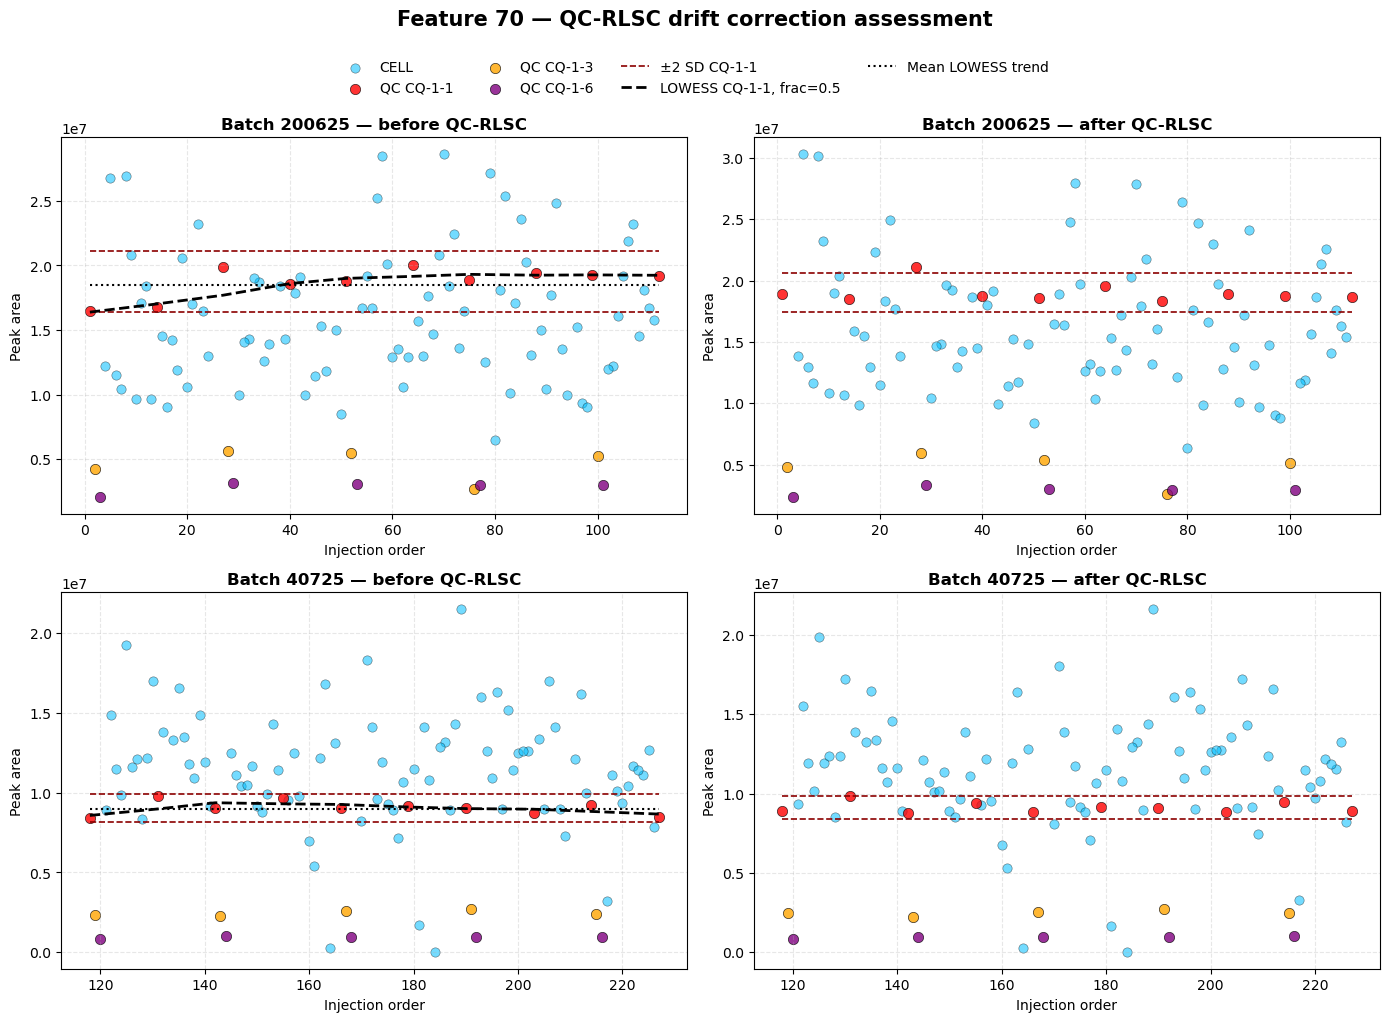

Figure exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\figures\preprocessing_analysis\05_QCRLSC_drift_correction_S\QCRLSC_feature_70_before_after.png


In [13]:
# ---------- Parameters ----------
QC_LABEL = "CQ-1-1"
LOWESS_FRAC = 0.5

# Features to visualize
# Use row ID values as strings or integers.
FEATURES_TO_PLOT = ["70"]

# ---------- Input / output files ----------
raw_file = DATA_PROCESSED / "04_CELL_filter1_qc_mean_nonzero.xlsx"
corrected_file = DATA_PROCESSED / "05_CELL_qcrlsc_corrected.xlsx"

figure_dir = OUTPUT_FIGURES / "05_QCRLSC_drift_correction"
figure_dir.mkdir(parents=True, exist_ok=True)

# ---------- Check input files ----------
if not raw_file.exists():
    raise FileNotFoundError(f"Raw pre-correction file not found: {raw_file}\n Please run Step 4 first.")

if not corrected_file.exists():
    raise FileNotFoundError(f"Corrected file not found: {corrected_file}\n Please run Step 5 first.")

# ---------- Load raw and corrected datasets ----------
raw_data = pd.read_excel(raw_file, sheet_name="filtered_data")
corrected_data = pd.read_excel(corrected_file, sheet_name="corrected_data")

# Remove empty columns, if present
raw_data = raw_data.loc[:, ~raw_data.columns.str.startswith("Unnamed")]
corrected_data = corrected_data.loc[:, ~corrected_data.columns.str.startswith("Unnamed")]

# ---------- Metadata and feature columns ----------
metadata_cols = [
    "sample_id",
    "raw_column",
    "batch",
    "sample_type",
    "condition",
    "experiment",
    "drug",
    "time",
    "time_h",
    "dilution",
    "replicate",
    "sample_group",
    "injection_order"]

metadata_cols = [col for col in metadata_cols if col in raw_data.columns]
required_cols = ["sample_id","batch", "sample_group", "injection_order"]
missing_raw_cols = [col for col in required_cols if col not in raw_data.columns]
missing_corr_cols = [col for col in required_cols if col not in corrected_data.columns]

if missing_raw_cols:
    raise ValueError(f"Missing required column(s) in raw data: {missing_raw_cols}")

if missing_corr_cols:
    raise ValueError(f"Missing required column(s) in corrected data: {missing_corr_cols}")

feature_cols = [col for col in raw_data.columns if col not in metadata_cols]

print(f"Available features: {len(feature_cols)}")
print(f"Selected features: {FEATURES_TO_PLOT}")


# ---------- Helper functions ----------
def resolve_feature_column(feature_id, columns):
    """
    Match a requested feature ID to the actual column name.
    Handles integer/string mismatches after Excel import.
    """
    feature_id_str = str(feature_id)
    for col in columns:
        if str(col) == feature_id_str:
            return col

    raise ValueError(f"Feature {feature_id} was not found in the dataset.")

def prepare_xy_unique(x_values, y_values):
    """
    Sort x/y values and aggregate duplicated injection orders by mean.
    """
    x_values = np.asarray(x_values, dtype=float)
    y_values = np.asarray(y_values, dtype=float)

    valid = (np.isfinite(x_values) & np.isfinite(y_values))
    x_values = x_values[valid]
    y_values = y_values[valid]

    order = np.argsort(x_values)
    x_sorted = x_values[order]
    y_sorted = y_values[order]

    x_unique = np.unique(x_sorted)
    y_aggregated = np.array([np.mean(y_sorted[x_sorted == x_val]) for x_val in x_unique])
    return x_unique, y_aggregated

def prepare_plot_data(data, feature_col, dataset_label):
    """
    Prepare a long-format table for plotting one feature.
    """
    plot_data = data[["sample_id", "batch", "sample_group", "injection_order", feature_col]].copy()
    plot_data["injection_order"] = pd.to_numeric(plot_data["injection_order"], errors="coerce")

    plot_data["intensity"] = pd.to_numeric(plot_data[feature_col],errors="coerce")
    plot_data["dataset"] = dataset_label
    return plot_data

def plot_feature_batch(plot_data, ax, title, show_lowess=False, show_reference_line=False):
    """
    Plot raw or corrected intensities for one feature and one batch.
    """
    qc_colors = {"CQ-1-1": "red", "CQ-1-3": "orange", "CQ-1-6": "purple"}
    cell_color = "deepskyblue"
    plot_data = plot_data.dropna(subset=["injection_order", "intensity"]).copy()

    sample_group = plot_data["sample_group"].astype(str)
    is_qc = sample_group.str.startswith("CQ-")

    qc_data = plot_data[is_qc].copy()
    cell_data = plot_data[~is_qc].copy()

    # Plot CELL samples
    if not cell_data.empty:
        ax.scatter(cell_data["injection_order"], cell_data["intensity"], 
                   label="CELL", color=cell_color, s=45, edgecolor="black", linewidth=0.4, alpha=0.55)

    # Plot QC samples by QC group
    if not qc_data.empty:
        for group in sorted(qc_data["sample_group"].dropna().unique()):
            subset = qc_data[qc_data["sample_group"] == group]

            ax.scatter(subset["injection_order"], subset["intensity"], label=f"QC {group}", color=qc_colors.get(str(group), "gray"), 
                       s=55, edgecolor="black", linewidth=0.5, alpha=0.8)

    # Reference QC group
    reference_qc = plot_data[plot_data["sample_group"] == QC_LABEL].copy()

    # Add ±2 SD lines for reference QC group
    if not reference_qc.empty:
        y_qc = reference_qc["intensity"].to_numpy(dtype=float)
        y_qc = y_qc[np.isfinite(y_qc)]

        if y_qc.size >= 2:
            mean_qc = np.mean(y_qc)
            sd_qc = np.std(y_qc, ddof=1)

            xmin = np.nanmin(plot_data["injection_order"])
            xmax = np.nanmax(plot_data["injection_order"])

            ax.hlines([mean_qc - 2 * sd_qc, mean_qc + 2 * sd_qc], xmin=xmin, xmax=xmax, 
                      colors="darkred", linestyles="dashed", linewidth=1.2, label="±2 SD CQ-1-1")

    # Add LOWESS trend on reference QC group
    if show_lowess and not reference_qc.empty:
        x_qc = reference_qc["injection_order"].to_numpy(dtype=float)
        y_qc = reference_qc["intensity"].to_numpy(dtype=float)

        x_fit, y_input = prepare_xy_unique(x_qc, y_qc)

        if len(x_fit) >= 4:
            y_fit = lowess(y_input, x_fit, frac=float(LOWESS_FRAC), is_sorted=True, return_sorted=False)
            ax.plot(x_fit, y_fit, color="black", linestyle="dashed", linewidth=2, label=f"LOWESS CQ-1-1, frac={LOWESS_FRAC}"
                    
            if show_reference_line:
                mean_fit = np.mean(y_fit)

                ax.hlines(mean_fit, xmin=np.nanmin(plot_data["injection_order"]), xmax=np.nanmax(plot_data["injection_order"]),
                          colors="black", linestyles=":", linewidth=1.5, label="Mean LOWESS trend")

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Injection order")
    ax.set_ylabel("Peak area")
    ax.grid(True, linestyle="--", alpha=0.3)

# ---------- Generate before/after plots ----------
for feature_id in FEATURES_TO_PLOT:
    feature_col = resolve_feature_column(feature_id, feature_cols)

    print(f"\nPlotting feature: {feature_id}")

    raw_plot = prepare_plot_data(raw_data, feature_col, dataset_label="Before QC-RLSC")
    corrected_plot = prepare_plot_data(corrected_data, feature_col, dataset_label="After QC-RLSC")
    batches = sorted(raw_plot["batch"].dropna().astype(str).unique())
    n_batches = len(batches)

    fig, axes = plt.subplots(n_batches, 2, figsize=(14, 4.8 * n_batches), sharex=False, sharey=False)

    if n_batches == 1:
        axes = np.array([axes])

    for row_idx, batch in enumerate(batches):
        raw_batch = raw_plot[raw_plot["batch"].astype(str) == batch]
        corrected_batch = corrected_plot[corrected_plot["batch"].astype(str) == ]

        plot_feature_batch(raw_batch, ax=axes[row_idx, 0], title=f"Batch {batch} — before QC-RLSC", show_lowess=True, show_reference_line=True)
        plot_feature_batch(corrected_batch, ax=axes[row_idx, 1], title=f"Batch {batch} — after QC-RLSC", show_lowess=False, show_reference_line=False)

    # Build a single legend for the full figure
    handles, labels = axes[0, 0].get_legend_handles_labels()
    unique_legend = dict(zip(labels, handles))

    fig.legend(unique_legend.values(), unique_legend.keys(), loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=False)
    fig.suptitle(f"Feature {feature_id} — QC-RLSC drift correction assessment", fontsize=15, fontweight="bold", y=1.06)
    plt.tight_layout()

    # ---------- Export figure ----------
    figure_file = figure_dir / f"QCRLSC_feature_{feature_id}_before_after.png"
    plt.savefig(figure_file, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Figure exported to: {figure_file}")

# 6. Second feature filtering after QC-RLSC correction

Features were further filtered after intra-batch QC-RLSC correction using two QC-based criteria: (i) RSD* above 30% in the reference QC group (`CQ-1-1`) in at least one batch, and (ii) non-positive Pearson correlation between dilution factor and QC intensity across diluted QC samples (`CQ-1-1`, `CQ-1-3`, `CQ-1-6`) in at least one batch.

In [14]:
# ---------- Parameters ----------
QC_LABEL = "CQ-1-1"
RSDSTAR_MAX = 30.0  # %

QC_GROUPS = ["CQ-1-1", "CQ-1-3", "CQ-1-6"]
QC_TO_DILUTION = {"CQ-1-1": 1.0, "CQ-1-3": 1 / 3, "CQ-1-6": 1 / 6}

PEARSON_R_MIN = 0.0

# To strictly reproduce the original script, keep this as False.
# If set to True, features with insufficient QC dilution points will also be removed.
REMOVE_NAN_DILUTION_CORRELATION = False

# ---------- Input / output files ----------
input_file = DATA_PROCESSED / "05_CELL_qcrlsc_corrected.xlsx"
output_file = DATA_PROCESSED / "06_CELL_filter2_qc_stability_filtered.xlsx"
removed_file = DATA_PROCESSED / "06_removed_features_filter2_qc_stability.xlsx"

# Create output directory if needed
output_file.parent.mkdir(parents=True, exist_ok=True)

# ---------- Check input file ----------
if not input_file.exists():
    raise FileNotFoundError(f"Input file not found: {input_file}\n Please run Step 5 first or check the processed data folder.")

# ---------- Load QC-RLSC-corrected dataset ----------
data = pd.read_excel(input_file, sheet_name="corrected_data")

# Remove empty columns, if present
data = data.loc[:, ~data.columns.str.startswith("Unnamed")]

# Ensure column names are strings
data.columns = data.columns.astype(str)

# ---------- Required metadata columns ----------
required_cols = ["batch", "sample_group"]

missing_cols = [col for col in required_cols if col not in data.columns]

if missing_cols:
    raise ValueError(f"Missing required column(s): {missing_cols}")

# ---------- Identify metadata and feature columns ----------
metadata_cols = [
    "sample_id",
    "raw_column",
    "batch",
    "sample_type",
    "condition",
    "experiment",
    "drug",
    "time",
    "time_h",
    "dilution",
    "replicate",
    "sample_group",
    "injection_order"]

metadata_cols = [col for col in metadata_cols if col in data.columns]
feature_cols = [col for col in data.columns if col not in metadata_cols]

if len(feature_cols) == 0:
    raise ValueError("No feature columns were detected after metadata column exclusion.")

# Convert feature intensities to numeric values
data[feature_cols] = data[feature_cols].apply(pd.to_numeric, errors="coerce")
print(f"Input features detected: {len(feature_cols)}")

# ---------- Helper functions ----------
def robust_rsd_star_percent(values):
    """
    Compute robust RSD* (%) using MAD/median:
    robust SD = 1.4826 x MAD
    RSD* = 100 x robust SD / |median|
    """
    values = pd.to_numeric(values, errors="coerce")
    values = values.dropna().astype(float).to_numpy()

    if values.size < 2:
        return np.nan

    median_value = np.median(values)

    if median_value == 0 or not np.isfinite(median_value):
        return np.nan

    mad = np.median(np.abs(values - median_value))
    robust_sd = 1.4826 * mad
    
    return 100.0 * robust_sd / abs(median_value)

def qc_dilution_pearson_r(batch_data, feature):
    """
    Compute Pearson correlation coefficient r between QC dilution factor
    and feature intensity within one batch.
    Note:
    This is Pearson r, not R².
    """
    qc_data = batch_data[batch_data["sample_group"].astype(str).isin(QC_GROUPS)].copy()
    if qc_data.empty:
        return np.nan, 0

    x = qc_data["sample_group"].astype(str).map(QC_TO_DILUTION)
    y = pd.to_numeric(qc_data[feature], errors="coerce")
    x = pd.to_numeric(x, errors="coerce")
    valid = (np.isfinite(x) & np.isfinite(y)
    x = x[valid].to_numpy(dtype=float)
    y = y[valid].to_numpy(dtype=float)

    n_points = len(x)

    if n_points < 3:
        return np.nan, n_points
    if np.nanstd(x) == 0 or np.nanstd(y) == 0:
        return np.nan, n_points
    pearson_r = np.corrcoef(x, y)[0, 1]

    return pearson_r, n_points

# ============================================================
# 6.1 Robust RSD* in reference QC samples
# ============================================================

reference_qc_data = data[data["sample_group"].astype(str) == QC_LABEL].copy()

if reference_qc_data.empty:
    raise ValueError(f"No QC samples found with sample_group == '{QC_LABEL}'.")

rsd_rows = []

for batch, batch_data in reference_qc_data.groupby("batch"):
    for feature in feature_cols:
        values = pd.to_numeric(batch_data[feature], errors="coerce")
        n_valid = values.dropna().shape[0]
        rsd_star = robust_rsd_star_percent(values)
        rsd_rows.append({"batch": batch, "feature": feature, "n_QC_reference": int(n_valid), "RSDstar_percent": rsd_star})
rsd_table = pd.DataFrame(rsd_rows)

# Features removed if RSD* > threshold in at least one batch
features_removed_rsd = (rsd_table.loc[rsd_table["RSDstar_percent"] > RSDSTAR_MAX, "feature"].dropna().unique().tolist()

# ============================================================
# 6.2 QC dilution-response correlation
# ============================================================

dilution_qc_data = data[data["sample_group"].astype(str).isin(QC_GROUPS)].copy()
if dilution_qc_data.empty:
    raise ValueError(f"No diluted QC samples found for groups: {QC_GROUPS}")
corr_rows = []

for batch, batch_data in dilution_qc_data.groupby("batch"):
    for feature in feature_cols:
        pearson_r, n_points = qc_dilution_pearson_r(batch_data, feature)
        corr_rows.append({"batch": batch, "feature": feature, "n_QC_dilution_points": int(n_points), "pearson_r_dilution": pearson_r})
dilution_corr_table = pd.DataFrame(corr_rows)

# Features removed if Pearson r <= threshold in at least one batch
remove_corr_mask = (dilution_corr_table["pearson_r_dilution"] <= PEARSON_R_MIN)

if REMOVE_NAN_DILUTION_CORRELATION:
    remove_corr_mask = (remove_corr_mask | dilution_corr_table["pearson_r_dilution"].isna())
features_removed_dilution_corr = (dilution_corr_table.loc[remove_corr_mask, "feature"].dropna().unique().tolist())

# ============================================================
# 6.3 Combine filtering criteria
# ============================================================

features_to_remove = sorted(set(features_removed_rsd) | set(features_removed_dilution_corr))
features_to_keep = [feature for feature in feature_cols if feature not in features_to_remove]
filtered_data = data[metadata_cols + features_to_keep].copy()

# ---------- Removed feature tables ----------
removed_rsd_table = (rsd_table[rsd_table["feature"].isin(features_removed_rsd)].sort_values(["feature", "batch"]).reset_index(drop=True))
removed_dilution_corr_table = (dilution_corr_table[dilution_corr_table["feature"]
    .isin(features_removed_dilution_corr)].sort_values(["feature", "batch"])*.reset_index(drop=True)*)

removed_union_table = pd.DataFrame({"feature": features_to_remove})

if not removed_union_table.empty:
    removed_union_table = (removed_union_table.merge(rsd_table.groupby("feature", as_index=False)["RSDstar_percent"].max()
        .rename(columns={"RSDstar_percent": "max_RSDstar_percent"}), on="feature", how="left")
        .merge(dilution_corr_table.groupby("feature", as_index=False)["pearson_r_dilution"].min()
        .rename(columns={"pearson_r_dilution": "min_pearson_r_dilution"}), on="feature", how="left"))

    removed_union_table["removed_by_RSDstar"] = (removed_union_table["feature"].isin(features_removed_rsd))
    removed_union_table["removed_by_dilution_correlation"] = (removed_union_table["feature"].isin(features_removed_dilution_corr))
# ---------- Summary table ----------
summary = pd.DataFrame({"item": ["Input features",
                                 "Reference QC group for RSD*",
                                 "RSD* threshold (%)",
                                 "QC groups for dilution correlation",
                                 "Pearson r threshold",
                                 "Remove NaN dilution correlation",
                                 "Features removed by RSD*",
                                 "Features removed by dilution correlation",
                                 "Features removed by union of criteria",
                                 "Retained features"],
                        "value": [len(feature_cols),
                                  QC_LABEL,
                                  RSDSTAR_MAX,
                                  ", ".join(QC_GROUPS),
                                  REMOVE_NAN_DILUTION_CORRELATION,
                                  len(features_removed_rsd),
                                  len(features_removed_dilution_corr),
                                  len(features_to_remove),
                                  len(features_to_keep)]})

# ---------- Export files ----------

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    filtered_data.to_excel(writer, index=False, sheet_name="filtered_data")
    summary.to_excel(writer, index=False, sheet_name="summary")

with pd.ExcelWriter(removed_file, engine="openpyxl") as writer:
    removed_union_table.to_excel(writer, index=False, sheet_name="removed_union")
    removed_rsd_table.to_excel(writer, index=False, sheet_name="removed_RSDstar_gt30")
    removed_dilution_corr_table.to_excel(writer, index=False, sheet_name="removed_pearson_r_le0")
    pd.DataFrame({"feature_RSDstar": features_removed_rsd}).to_excel(writer, index=False, sheet_name="list_RSDstar")
    pd.DataFrame({"feature_dilution_correlation": features_removed_dilution_corr}).to_excel(writer, index=False, sheet_name="list_dilution_corr")
    pd.DataFrame({"feature_union": features_to_remove}).to_excel(writer, index=False, sheet_name="list_union")
    
# ---------- Display summary ----------
print(summary.to_string(index=False))
print("\nSecond QC-based filtering completed.")
print(f"Filtered dataset exported to: {output_file}")
print(f"Removed features exported to: {removed_file}")

Input features detected: 2066
                                    item                  value
                          Input features                   2066
             Reference QC group for RSD*                 CQ-1-1
                      RSD* threshold (%)                   30.0
      QC groups for dilution correlation CQ-1-1, CQ-1-3, CQ-1-6
                     Pearson r threshold                    0.0
         Remove NaN dilution correlation                  False
                Features removed by RSD*                    337
Features removed by dilution correlation                    155
   Features removed by union of criteria                    438
                       Retained features                   1628

Second QC-based filtering completed.
Filtered dataset exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\06_CELL_filter2_qc_stability_filtered_S.xlsx
Removed features exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\process

# 7. Inter-batch correction using reference quality control (QC) sample medians

Residual differences between batches were corrected using the median intensity of the reference QC group (`CQ-1-1`). For each variable, batch-specific correction factors were calculated relative to a reference batch and applied to all samples in the corresponding batch.

In [15]:
# ---------- Parameters ----------
QC_LABEL = "CQ-1-1"

# If None, the first batch in alphabetical/numerical order is used.
REFERENCE_BATCH = None

# How to handle invalid correction factors:
# "keep_original" = replace invalid factors by 1, so values remain unchanged
# "set_nan" = keep NaN factors, so corrected values become NaN
INVALID_FACTOR_ACTION = "keep_original"

# ---------- Input / output files ----------
input_file = DATA_PROCESSED / "06_CELL_filter2_qc_stability_filtered.xlsx"
output_file = DATA_PROCESSED / "07_CELL_interbatch_corrected.xlsx"

# Create output directory if needed
output_file.parent.mkdir(parents=True, exist_ok=True)

# ---------- Check input file ----------
if not input_file.exists():
    raise FileNotFoundError(f"Input file not found: {input_file}\n" "Please run Step 6 first or check the processed data folder.")

# ---------- Load filtered dataset ----------
data = pd.read_excel(input_file, sheet_name="filtered_data")

# Remove empty columns, if present
data = data.loc[:, ~data.columns.str.startswith("Unnamed")]

# Ensure column names are strings
data.columns = data.columns.astype(str)

# ---------- Required metadata columns ----------
required_cols = ["batch", "sample_group"]
missing_cols = [col for col in required_cols if col not in data.columns]
if missing_cols:
    raise ValueError(f"Missing required column(s): {missing_cols}")

# ---------- Identify metadata and feature columns ----------
metadata_cols = ["sample_id", "raw_column", "batch", "sample_type", "condition", "experiment", "drug", "time", "time_h", "dilution", "replicate", "sample_group", "injection_order"]
metadata_cols = [col for col in metadata_cols if col in data.columns]
feature_cols = [col for col in data.columns if col not in metadata_cols]
if len(feature_cols) == 0:
    raise ValueError("No feature columns were detected after metadata column exclusion.")

# Convert feature intensities to numeric values
data[feature_cols] = data[feature_cols].apply(pd.to_numeric, errors="coerce")

# Use a string version of batch for robust matching
data["_batch_for_correction"] = data["batch"].astype(str)

#---------- Extract reference QC samples ----------
qc_data = data[data["sample_group"].astype(str) == QC_LABEL].copy()
if qc_data.empty:
    raise ValueError(f"No QC samples found with sample_group == '{QC_LABEL}'.")

# ---------- Identify batches ----------
batches = sorted(data["_batch_for_correction"].dropna().unique())
if len(batches) == 0:
    raise ValueError("No analytical batches were found.")
if REFERENCE_BATCH is None:
    reference_batch = batches[0]
else:
    reference_batch = str(REFERENCE_BATCH)
if reference_batch not in batches:
    raise ValueError(f"Reference batch '{reference_batch}' was not found. " f"Available batches: {batches}")
print(f"Analytical batches: {batches}")
print(f"Reference batch: {reference_batch}")
print(f"Reference QC group: {QC_LABEL}")

# ---------- Compute QC medians by batch ----------
qc_medians = (qc_data.groupby("_batch_for_correction")[feature_cols].median(numeric_only=True))
if reference_batch not in qc_medians.index:
    raise ValueError(f"Reference batch '{reference_batch}' has no QC samples " f"for QC group '{QC_LABEL}'.")
reference_medians = qc_medians.loc[reference_batch]

# ---------- Compute correction factors ----------
# Factor = reference QC median / batch QC median
correction_factors = 1 / qc_medians.divide(reference_medians, axis=1)

# Replace infinite values by NaN
correction_factors = correction_factors.replace([np.inf, -np.inf], np.nan)

# ---------- Identify invalid correction factors ----------
invalid_factor_mask = (correction_factors.isna() | ~np.isfinite(correction_factors))
invalid_factor_rows = []
for batch in correction_factors.index:
    invalid_features = correction_factors.columns[invalid_factor_mask.loc[batch]].tolist()
    for feature in invalid_features:
        invalid_factor_rows.append({"batch": batch, "feature": feature, "qc_median_batch": qc_medians.loc[batch, feature], "qc_median_reference_batch": reference_medians[feature], "correction_factor": correction_factors.loc[batch, feature], "comment": "Invalid correction factor"})
invalid_factors = pd.DataFrame(invalid_factor_rows)

# ---------- Handle invalid correction factors ----------
if INVALID_FACTOR_ACTION == "keep_original":
    correction_factors = correction_factors.mask(invalid_factor_mask, 1.0)
elif INVALID_FACTOR_ACTION == "set_nan":
    correction_factors = correction_factors.mask(invalid_factor_mask, np.nan)
else:
    raise ValueError("Invalid INVALID_FACTOR_ACTION. " "Use 'keep_original' or 'set_nan'.")

# ---------- Apply inter-batch correction ----------
corrected_data = data.copy()
for batch in batches:
    if batch not in correction_factors.index:
        print(f"Warning: batch {batch} has no QC median. " "No inter-batch correction applied.")
        continue
    batch_mask = corrected_data["_batch_for_correction"] == batch
    batch_factors = correction_factors.loc[batch]
    corrected_data.loc[batch_mask, feature_cols] = (corrected_data.loc[batch_mask, feature_cols].mul(batch_factors, axis=1))

# Remove temporary batch column before export
corrected_data = corrected_data.drop(columns=["_batch_for_correction"])

# ---------- Summary table ----------
summary = pd.DataFrame({"item": ["Input features", "Reference QC group", "Analytical batches", "Reference batch", "Invalid factor action", "Invalid correction factors", "Corrected samples"], "value": [len(feature_cols), QC_LABEL, ", ".join(batches), reference_batch, INVALID_FACTOR_ACTION, invalid_factors.shape[0], corrected_data.shape[0]]})

# ---------- Export files ----------
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    corrected_data.to_excel(writer, index=False, sheet_name="corrected_data")
    qc_medians.to_excel(writer, sheet_name="QC_medians")
    correction_factors.to_excel(writer, sheet_name="correction_factors")
    invalid_factors.to_excel(writer, index=False, sheet_name="invalid_factors")
    summary.to_excel(writer, index=False, sheet_name="summary")

# ---------- Display summary ----------
print(summary.to_string(index=False))
print("\nInter-batch correction completed.")
print(f"Corrected dataset exported to: {output_file}")

C:\Users\fourn\AppData\Local\Temp\ipykernel_8728\239990532.py:83: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data["_batch_for_correction"] = data["batch"].astype(str)


Analytical batches: ['200625', '40725']
Reference batch: 200625
Reference QC group: CQ-1-1
                      item         value
            Input features          1628
        Reference QC group        CQ-1-1
        Analytical batches 200625, 40725
           Reference batch        200625
     Invalid factor action keep_original
Invalid correction factors           174
         Corrected samples           212

Inter-batch correction completed.
Corrected dataset exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\07_CELL_interbatch_corrected_S.xlsx


## 7.1 Visual assessment of intra- and inter-batch correction

Selected features: ['25926']

Plotting feature: 25926


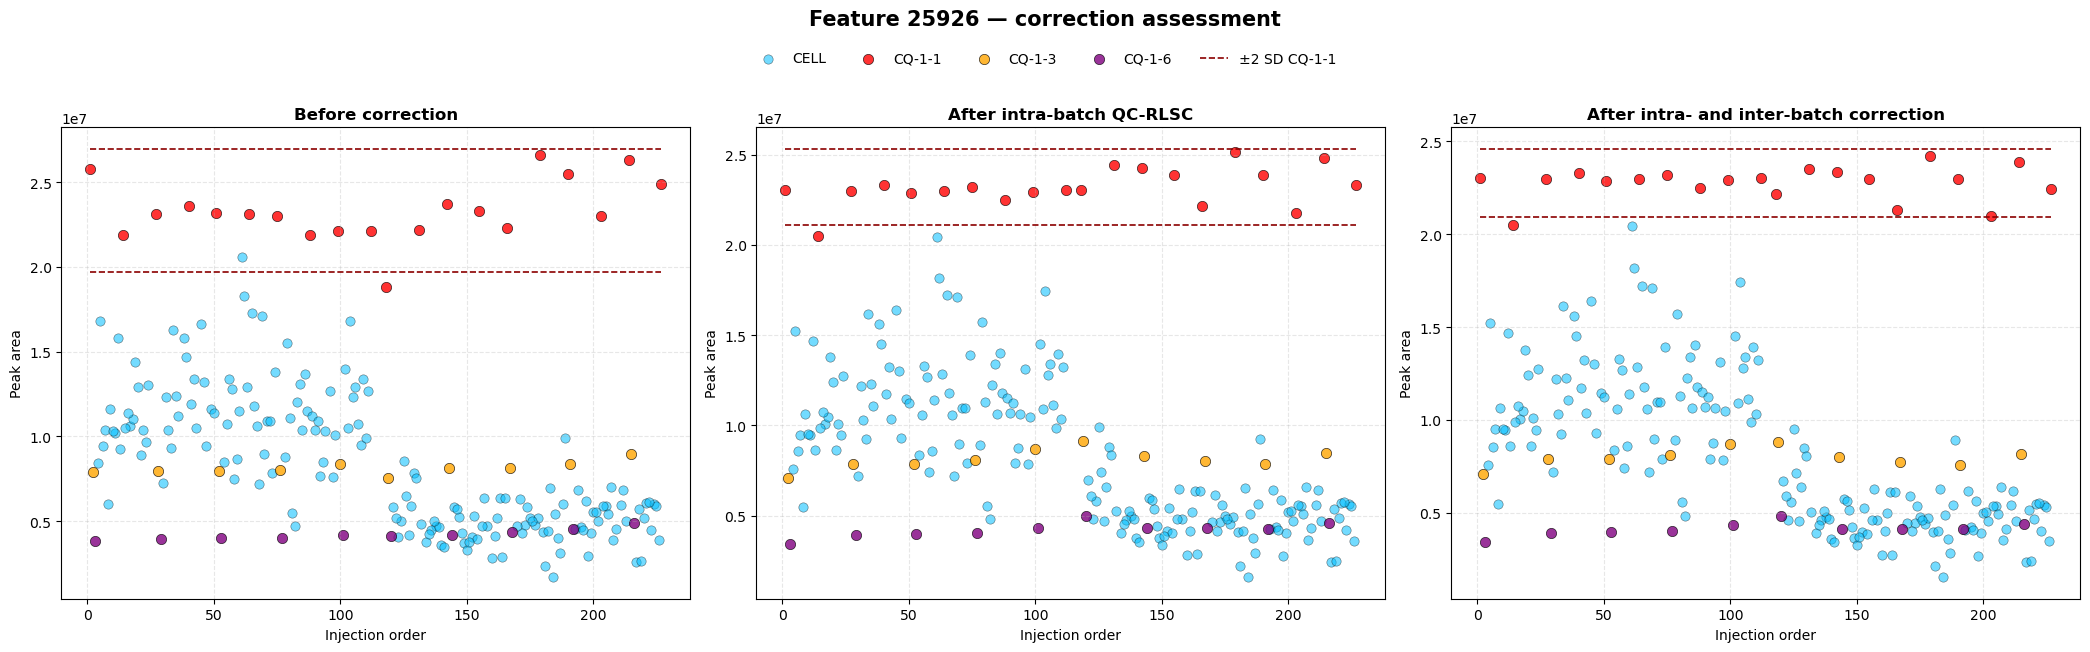

Figure exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\figures\preprocessing_analysis\07_intra_inter_batch_correction\feature_25926_raw_intra_inter_correction.png


In [17]:
# ---------- Parameters ----------
QC_LABEL = "CQ-1-1"

# Features to visualize
# Use row ID values as strings or integers.
FEATURES_TO_PLOT = ["25926"]

# ---------- Input / output files ----------
raw_file = DATA_PROCESSED / "04_CELL_filter1_qc_mean_nonzero.xlsx"
corrected_intra_file = DATA_PROCESSED / "05_CELL_qcrlsc_corrected.xlsx"
corrected_intra_inter_file = DATA_PROCESSED / "07_CELL_interbatch_corrected.xlsx"
figure_dir = OUTPUT_FIGURES / "07_intra_inter_batch_correction"
figure_dir.mkdir(parents=True, exist_ok=True)

# ---------- Check input files ----------
for file in [raw_file, corrected_intra_file, corrected_intra_inter_file]:
    if not file.exists():
        raise FileNotFoundError(f"Input file not found: {file}\n" "Please check that the previous preprocessing steps were run.")

# ---------- Load datasets ----------
raw_data = pd.read_excel(raw_file, sheet_name="filtered_data")
intra_corrected_data = pd.read_excel(corrected_intra_file, sheet_name="corrected_data")
intra_inter_corrected_data = pd.read_excel(corrected_intra_inter_file, sheet_name="corrected_data")

# Remove empty columns, if present
raw_data = raw_data.loc[:, ~raw_data.columns.str.startswith("Unnamed")]
intra_corrected_data = intra_corrected_data.loc[:, ~intra_corrected_data.columns.str.startswith("Unnamed")]
intra_inter_corrected_data = intra_inter_corrected_data.loc[:, ~intra_inter_corrected_data.columns.str.startswith("Unnamed")]

# Harmonize column names as strings
raw_data.columns = raw_data.columns.astype(str)
intra_corrected_data.columns = intra_corrected_data.columns.astype(str)
intra_inter_corrected_data.columns = intra_inter_corrected_data.columns.astype(str)
print(f"Selected features: {FEATURES_TO_PLOT}")

# ---------- Helper functions ----------
def resolve_feature_column(feature_id, dataframes):
    """
    Match a requested feature ID to the actual column name
    and check that it is present in all datasets.
    """
    feature_id = str(feature_id)
    for dataframe_name, dataframe in dataframes.items():
        if feature_id not in dataframe.columns:
            raise ValueError(f"Feature {feature_id} was not found in {dataframe_name}. " "It may have been removed during filtering.")
    return feature_id

def prepare_correction_plot_data(data, feature_id, dataset_label):
    """
    Prepare plotting table for one feature and one correction level.
    """
    required_cols = ["sample_id", "injection_order", "sample_group", "batch", feature_id]
    missing_cols = [col for col in required_cols if col not in data.columns]
    if missing_cols:
        raise ValueError(f"Missing required column(s) for plotting: {missing_cols}")
    plot_data = data[required_cols].copy()
    plot_data["injection_order"] = pd.to_numeric(plot_data["injection_order"], errors="coerce")
    plot_data["intensity"] = pd.to_numeric(plot_data[feature_id], errors="coerce")
    plot_data["dataset"] = dataset_label
    return plot_data

def plot_correction_panel(plot_data, title, ax):
    """
    Plot QC and CELL intensities according to injection order.
    """
    qc_colors = {"CQ-1-1": "red", "CQ-1-3": "orange", "CQ-1-6": "purple"}
    cell_color = "deepskyblue"
    plot_data = plot_data.dropna(subset=["injection_order", "intensity"]).copy()
    sample_group = plot_data["sample_group"].astype(str)
    is_qc = sample_group.str.startswith("CQ-")
    qc_data = plot_data[is_qc].copy()
    cell_data = plot_data[~is_qc].copy()
    
    # Plot CELL samples
    if not cell_data.empty:
        ax.scatter(cell_data["injection_order"], cell_data["intensity"], label="CELL", color=cell_color, s=45, edgecolor="black", linewidth=0.4, alpha=0.55)
    
    # Plot QC samples by QC group
    if not qc_data.empty:
        for group in sorted(qc_data["sample_group"].dropna().astype(str).unique()):
            subset = qc_data[qc_data["sample_group"].astype(str) == group]
            ax.scatter(subset["injection_order"], subset["intensity"], label=group, color=qc_colors.get(group, "gray"), s=55, edgecolor="black", linewidth=0.5, alpha=0.8)
    
    # Add ±2 SD lines for CQ-1-1
    reference_qc = plot_data[plot_data["sample_group"].astype(str) == QC_LABEL].copy()
    if not reference_qc.empty:
        y_qc = reference_qc["intensity"].to_numpy(dtype=float)
        y_qc = y_qc[np.isfinite(y_qc)]
        if y_qc.size >= 2:
            mean_qc = np.mean(y_qc)
            sd_qc = np.std(y_qc, ddof=1)
            ax.hlines([mean_qc - 2 * sd_qc, mean_qc + 2 * sd_qc], xmin=np.nanmin(plot_data["injection_order"]), xmax=np.nanmax(plot_data["injection_order"]), colors="darkred", linestyles="dashed", linewidth=1.2, label="±2 SD CQ-1-1")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Injection order")
    ax.set_ylabel("Peak area")
    ax.grid(True, linestyle="--", alpha=0.3)

# ---------- Generate correction comparison plots ----------
datasets = {"raw_data": raw_data, "intra_corrected_data": intra_corrected_data, "intra_inter_corrected_data": intra_inter_corrected_data}
for feature_id in FEATURES_TO_PLOT:
    feature_id = resolve_feature_column(feature_id, datasets)
    print(f"\nPlotting feature: {feature_id}")
    plot_raw = prepare_correction_plot_data(raw_data, feature_id, dataset_label="Before correction")
    plot_intra = prepare_correction_plot_data(intra_corrected_data, feature_id, dataset_label="After intra-batch correction")
    plot_intra_inter = prepare_correction_plot_data(intra_inter_corrected_data, feature_id, dataset_label="After intra- and inter-batch correction")
    fig, axes = plt.subplots(1, 3, figsize=(21, 6), sharey=False)
    plot_correction_panel(plot_raw, "Before correction", axes[0])
    plot_correction_panel(plot_intra, "After intra-batch QC-RLSC", axes[1])
    plot_correction_panel(plot_intra_inter, "After intra- and inter-batch correction", axes[2])
    
    # Create one shared legend
    handles, labels = axes[1].get_legend_handles_labels()
    unique_legend = dict(zip(labels, handles))
    fig.legend(unique_legend.values(), unique_legend.keys(), loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=5, frameon=False)
    fig.suptitle(f"Feature {feature_id} — correction assessment", fontsize=15, fontweight="bold", y=1.08)
    plt.tight_layout()
    
    # ---------- Export figure ----------
    figure_file = figure_dir / f"feature_{feature_id}_raw_intra_inter_correction.png"
    plt.savefig(figure_file, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Figure exported to: {figure_file}")

# 8. Final filtering of non-informative features in CELL samples

After intra- and inter-batch correction, features with a median intensity equal to zero across CELL samples were removed. This final filtering step was used to discard non-informative features that remained undetected or mostly absent in biological samples.

In [18]:
# ---------- Parameters ----------
CELL_LABEL = "CELL"

# ---------- Input / output files ----------
input_file = DATA_PROCESSED / "07_CELL_interbatch_corrected.xlsx"
output_file = DATA_PROCESSED / "08_CELL_final_cleaned_dataset.xlsx"
removed_file = DATA_PROCESSED / "08_removed_features_cell_median_zero.xlsx"

# Create output directory if needed
output_file.parent.mkdir(parents=True, exist_ok=True)

# ---------- Check input file ----------
if not input_file.exists():
    raise FileNotFoundError(f"Input file not found: {input_file}\n" "Please run Step 7 first or check the processed data folder.")

# ---------- Load inter-batch corrected dataset ----------
data = pd.read_excel(input_file, sheet_name="corrected_data")

# Remove empty columns, if present
data = data.loc[:, ~data.columns.str.startswith("Unnamed")]

# Ensure column names are strings
data.columns = data.columns.astype(str)

# ---------- Identify CELL column ----------
if "sample_type" in data.columns:
    sample_type_col = "sample_type"
elif "type" in data.columns:
    sample_type_col = "type"
else:
    raise KeyError("No sample type column found. Expected 'sample_type' or 'type'.")

# ---------- Identify metadata and feature columns ----------
metadata_cols = ["sample_id", "raw_column", "batch", "sample_type", "type", "condition", "experiment", "exp", "drug", "time", "time_h", "dilution", "replicate", "sample_group", "injection_order"]
metadata_cols = [col for col in metadata_cols if col in data.columns]
feature_cols = [col for col in data.columns if col not in metadata_cols]
if len(feature_cols) == 0:
    raise ValueError("No feature columns were detected after metadata column exclusion.")

# Convert feature intensities to numeric values
data[feature_cols] = data[feature_cols].apply(pd.to_numeric, errors="coerce")
print(f"Input features detected: {len(feature_cols)}")

# ---------- Extract CELL samples ----------
cell_data = data[data[sample_type_col].astype(str).str.upper() == CELL_LABEL].copy()
if cell_data.empty:
    raise ValueError(f"No CELL samples found using column '{sample_type_col}'.")

# ---------- Compute median intensity across CELL samples ----------
cell_medians = cell_data[feature_cols].median(axis=0, skipna=True)
cell_median_table = (cell_medians.rename("median_CELL_intensity").reset_index().rename(columns={"index": "feature"}))

# ---------- Identify features to keep/remove ----------
features_to_remove = (cell_median_table.loc[cell_median_table["median_CELL_intensity"] == 0, "feature"].astype(str).tolist())
features_to_keep = [feature for feature in feature_cols if feature not in features_to_remove]

# ---------- Create output tables ----------
final_data = data[metadata_cols + features_to_keep].copy()
removed_features_data = data[metadata_cols + features_to_remove].copy()
removed_feature_summary = cell_median_table[cell_median_table["feature"].isin(features_to_remove)].copy()
removed_feature_summary["removal_reason"] = ("Median intensity across CELL samples equal to 0")

# ---------- Summary table ----------
summary = pd.DataFrame({"item": ["Input features", "CELL samples", "Filtering criterion", "Removed features", "Retained features"], "value": [len(feature_cols), cell_data.shape[0], "Median intensity across CELL samples == 0", len(features_to_remove), len(features_to_keep)]})

# ---------- Export files ----------
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    final_data.to_excel(writer, index=False, sheet_name="final_cleaned_data")
    cell_median_table.to_excel(writer, index=False, sheet_name="CELL_feature_medians")
    removed_feature_summary.to_excel(writer, index=False, sheet_name="removed_features")
    summary.to_excel(writer, index=False, sheet_name="summary")
with pd.ExcelWriter(removed_file, engine="openpyxl") as writer:
    removed_features_data.to_excel(writer, index=False, sheet_name="removed_feature_values")
    removed_feature_summary.to_excel(writer, index=False, sheet_name="removed_feature_summary")
    summary.to_excel(writer, index=False, sheet_name="summary")

# ---------- Display summary ----------
print(summary.to_string(index=False))
print("\nFinal CELL median filtering completed.")
print(f"Final cleaned dataset exported to: {output_file}")
print(f"Removed features exported to: {removed_file}")

Input features detected: 1628
               item                                     value
     Input features                                      1628
       CELL samples                                       172
Filtering criterion Median intensity across CELL samples == 0
   Removed features                                       315
  Retained features                                      1313

Final CELL median filtering completed.
Final cleaned dataset exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\08_CELL_final_cleaned_dataset_S.xlsx
Removed features exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\08_removed_features_cell_median_zero_S.xlsx


# 9. PCA-based quality control assessment

PCA was used as a quality control visualization to assess QC sample clustering after the full preprocessing workflow.

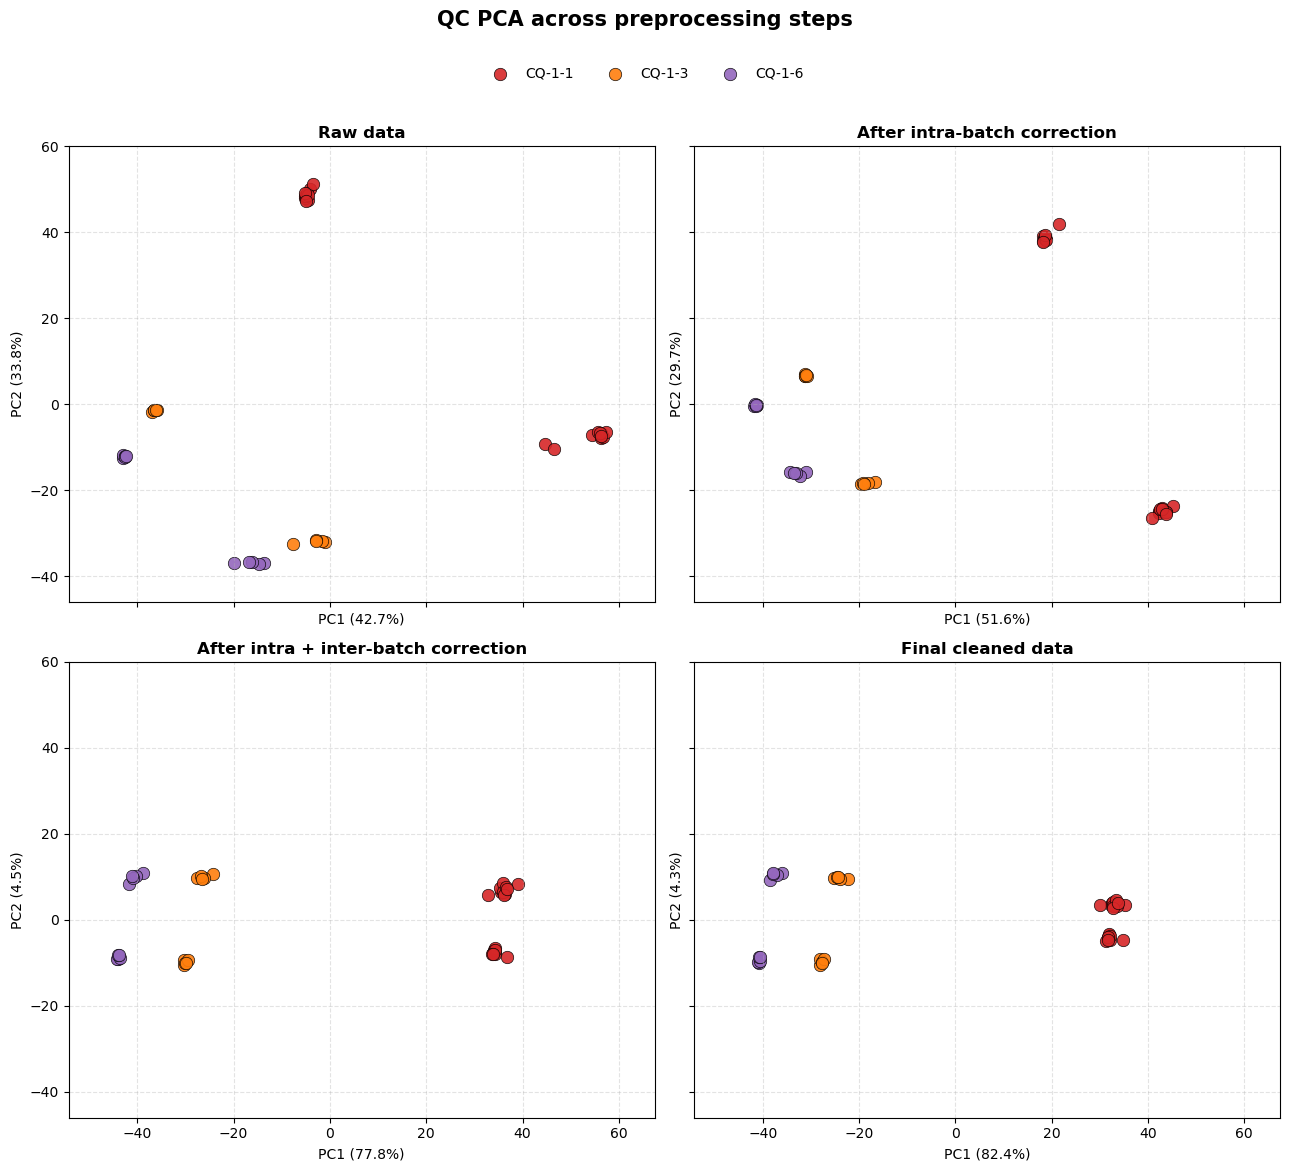

QC PCA across preprocessing steps completed.
                 preprocessing_stage  n_QC_samples  n_input_features  n_features_used_for_PCA  log10_transform missing_value_imputation
                            Raw data            40              2807                     2743            False                        0
        After intra-batch correction            40              2066                     2066            False                        0
After intra + inter-batch correction            40              1628                     1628            False                        0
                  Final cleaned data            40              1313                     1313            False                        0

PCA results exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\09_qc_pca_preprocessing_steps.xlsx
PCA figure exported to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\figures\preprocessing_analysis\09_QC_PCA_preprocessing_steps.png


In [20]:
# ---------- Parameters ----------
QC_GROUPS = ["CQ-1-1", "CQ-1-3", "CQ-1-6"]
qc_colors = {"CQ-1-1": "#D62728", "CQ-1-3": "#FF7F0E", "CQ-1-6": "#9467BD"}

# Keep False to reproduce the original PCA logic.
LOG10_TRANSFORM = False
PSEUDOCOUNT = 1.0

# ---------- Input files ----------
datasets_info = {"Raw data": {"file": DATA_PROCESSED / "03_CELL_formatted_dataset.xlsx", "sheet": "formatted_data"}, "After intra-batch correction": {"file": DATA_PROCESSED / "05_CELL_qcrlsc_corrected.xlsx", "sheet": "corrected_data"}, "After intra + inter-batch correction": {"file": DATA_PROCESSED / "07_CELL_interbatch_corrected.xlsx", "sheet": "corrected_data"}, "Final cleaned data": {"file": DATA_PROCESSED / "08_CELL_final_cleaned_dataset.xlsx", "sheet": "final_cleaned_data"}}

# ---------- Output files ----------
output_file = DATA_PROCESSED / "09_qc_pca_preprocessing_steps.xlsx"
figure_file = OUTPUT_FIGURES / "09_QC_PCA_preprocessing_steps.png"
figure_file.parent.mkdir(parents=True, exist_ok=True)
output_file.parent.mkdir(parents=True, exist_ok=True)

# ---------- Metadata columns ----------
metadata_cols_reference = [
    "sample_id",
    "raw_column",
    "batch",
    "sample_type",
    "condition",
    "experiment",
    "drug",
    "time",
    "time_h",
    "dilution",
    "replicate",
    "sample_group",
    "injection_order",
    
    # Compatibility with older files
    "raw_name",
    "raw_name.1",
    "type",
    "exp"
]

# ---------- PCA calculation ----------
def compute_qc_pca_scores(data, stage_name):
    """
    Compute PCA scores for QC samples only.
    PCA is computed independently for each preprocessing stage.
    """
    data = data.copy()
    data.columns = data.columns.astype(str)
    if "sample_group" not in data.columns:
        raise ValueError(f"Missing 'sample_group' column in dataset: {stage_name}")
    metadata_cols = [col for col in metadata_cols_reference if col in data.columns]
    feature_cols = [col for col in data.columns if col not in metadata_cols]
    if len(feature_cols) < 2:
        raise ValueError(f"Not enough feature columns for PCA in dataset: {stage_name}")
    qc_data = data[data["sample_group"].astype(str).isin(QC_GROUPS)].copy()
    if qc_data.empty:
        raise ValueError(f"No QC samples found in dataset: {stage_name}")
    X = qc_data[feature_cols].apply(pd.to_numeric, errors="coerce")
    
    # Optional log transformation
    if LOG10_TRANSFORM:
        X = X.mask(X < 0, np.nan)
        X = np.log10(X + PSEUDOCOUNT)
    
    # Reproduce original code behavior: missing values replaced by 0
    X = X.fillna(0)
    
    # Remove constant features, which cannot contribute to PCA
    valid_features = X.columns[X.std(axis=0) > 0]
    X = X[valid_features]
    if X.shape[1] < 2:
        raise ValueError(f"Not enough non-constant features for PCA in dataset: {stage_name}")
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    pca = PCA(n_components=2)
    pcs = pca.fit_transform(X_scaled)
    pca_scores = qc_data[metadata_cols].copy()
    pca_scores["preprocessing_stage"] = stage_name
    pca_scores["PC1"] = pcs[:, 0]
    pca_scores["PC2"] = pcs[:, 1]
    explained_variance = pd.DataFrame({"preprocessing_stage": [stage_name, stage_name], "PC": ["PC1", "PC2"], "explained_variance_percent": pca.explained_variance_ratio_[:2] * 100})
    summary = pd.DataFrame({"preprocessing_stage": [stage_name], "n_QC_samples": [qc_data.shape[0]], "n_input_features": [len(feature_cols)], "n_features_used_for_PCA": [X.shape[1]], "log10_transform": [LOG10_TRANSFORM], "missing_value_imputation": ["0"]})
    return pca_scores, explained_variance, summary

# ---------- Load datasets and compute PCA ----------
pca_results = {}
all_scores = []
all_variance = []
all_summary = []
for stage_name, info in datasets_info.items():
    file_path = info["file"]
    sheet_name = info["sheet"]
    if not file_path.exists():
        raise FileNotFoundError(f"Input file not found for stage '{stage_name}': {file_path}")
    data = pd.read_excel(file_path, sheet_name=sheet_name)
    data = data.loc[:, ~data.columns.str.startswith("Unnamed")]
    pca_scores, explained_variance, summary = compute_qc_pca_scores(data, stage_name)
    pca_results[stage_name] = {"scores": pca_scores, "variance": explained_variance, "summary": summary}
    all_scores.append(pca_scores)
    all_variance.append(explained_variance)
    all_summary.append(summary)
combined_scores = pd.concat(all_scores, ignore_index=True)
combined_variance = pd.concat(all_variance, ignore_index=True)
combined_summary = pd.concat(all_summary, ignore_index=True)

# ---------- Define shared plot limits ----------
all_pc1 = combined_scores["PC1"].to_numpy(dtype=float)
all_pc2 = combined_scores["PC2"].to_numpy(dtype=float)
x_min, x_max = np.nanmin(all_pc1), np.nanmax(all_pc1)
y_min, y_max = np.nanmin(all_pc2), np.nanmax(all_pc2)
x_margin = 0.10 * (x_max - x_min)
y_margin = 0.10 * (y_max - y_min)
xlim = [x_min - x_margin, x_max + x_margin]
ylim = [y_min - y_margin, y_max + y_margin]

# ---------- Plot PCA panels ----------
stage_order = list(datasets_info.keys())
fig, axes = plt.subplots(2, 2, figsize=(13, 11), sharex=True, sharey=True)
axes = axes.flatten()
for ax, stage_name in zip(axes, stage_order):
    scores = pca_results[stage_name]["scores"]
    variance = pca_results[stage_name]["variance"]
    pc1_var = variance.loc[variance["PC"] == "PC1", "explained_variance_percent"].iloc[0]
    pc2_var = variance.loc[variance["PC"] == "PC2", "explained_variance_percent"].iloc[0]
    for qc_group in QC_GROUPS:
        subset = scores[scores["sample_group"].astype(str) == qc_group]
        if subset.empty:
            continue
        ax.scatter(subset["PC1"], subset["PC2"], label=qc_group, color=qc_colors.get(qc_group, "gray"), s=80, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_title(stage_name, fontsize=12, fontweight="bold")
    ax.set_xlabel(f"PC1 ({pc1_var:.1f}%)")
    ax.set_ylabel(f"PC2 ({pc2_var:.1f}%)")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.grid(True, linestyle="--", alpha=0.35)

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()
unique_legend = dict(zip(labels, handles))
fig.legend(unique_legend.values(), unique_legend.keys(), loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=len(QC_GROUPS), frameon=False)
fig.suptitle("QC PCA across preprocessing steps", fontsize=15, fontweight="bold", y=1.06)
plt.tight_layout()
plt.savefig(figure_file, dpi=300, bbox_inches="tight")
plt.show()

# ---------- Export PCA results to one Excel file ----------
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    combined_scores.to_excel(writer, sheet_name="PCA_scores_all", index=False)
    combined_variance.to_excel(writer, sheet_name="explained_variance", index=False)
    combined_summary.to_excel(writer, sheet_name="summary", index=False)
    for stage_name in stage_order:
        safe_sheet_name = (stage_name.replace(" ", "_").replace("+", "plus").replace("-", "_"))[:31]
        pca_results[stage_name]["scores"].to_excel(writer, sheet_name=safe_sheet_name, index=False)

# ---------- Display summary ----------
print("QC PCA across preprocessing steps completed.")
print(combined_summary.to_string(index=False))
print(f"\nPCA results exported to: {output_file}")
print(f"PCA figure exported to: {figure_file}")